# Single-frame ResNet50 steering (global 2048 features)

Compare raw PID steering with training targets that interpolate isolated spikes. Run the cells in order after preparing the seeded indices as described in `doc/donkeycar/data.md`. The pretrained ResNet50 backbone stays frozen. All linear heads use identical initialization and minibatch order. Select each checkpoint by MAE on original validation commands and score it on held-out road seeds.

## Training recipes

| Recipe | Training label on spike frames | Spike weight | Large non-spike weight |
| --- | --- | ---: | ---: |
| `raw` | `raw` | 1 | 1 |
| `raw_x2` | `raw` | 1 | 2 |
| `raw_x4` | `raw` | 1 | 4 |
| `downweighted_x1` | `raw` | 0.1 | 1 |
| `downweighted_x2` | `raw` | 0.1 | 2 |
| `downweighted_x4` | `raw` | 0.1 | 4 |
| `smoothed_x1` | `target` | 1 | 1 |
| `smoothed_x2` | `target` | 1 | 2 |
| `smoothed_x4` | `target` | 1 | 4 |

On isolated spikes, `target` is the mean of the preceding and following raw commands. All other frames retain `raw`. A large turn has absolute raw steering of at least 0.3. Non-spike frames below this threshold have weight 1.

In [1]:
from donkeycar_app.checkpoints import checkpoint_recipe, export_best_checkpoint
from donkeycar_app.dataset import STEERING_RECIPES
from pathlib import Path
import numpy as np
from PIL import Image
from mydezero import cuda, no_grad, test_mode
from mydezero.models import ResNet50, VGG16
from mydezero.layers import Linear

class GlobalSteeringResNet(ResNet50):
    def __init__(self, pretrained=False):
        super().__init__(pretrained=pretrained)
        self.fc6 = Linear(1, in_size=2048)

    def steer(self, rgb_frame):
        pixels = VGG16.preprocess(Image.fromarray(rgb_frame), size=None)
        xp = cuda.get_array_module(self.fc6.W.data)
        with test_mode(), no_grad():
            prediction = self(xp.asarray(np.ascontiguousarray(pixels[None])))
            return float(xp.clip(prediction.data, -1, 1).item())

NOTEBOOK_NAME = "resnet50_single_frame_global_2048"


def load_steering_model(checkpoint, use_gpu=True, *, recipe=None):
    checkpoint = Path(checkpoint)
    recipe = checkpoint_recipe(checkpoint, recipe)
    model = GlobalSteeringResNet()
    model.load_weights(checkpoint)
    if model.fc6.W.shape != (2048, 1):
        raise ValueError("Expected a 2048-to-1 steering head")
    if use_gpu and cuda.gpu_enable and cuda.cupy.is_available():
        model.to_gpu()
    multipliers = {"raw_x1": 1}  # Older checkpoints
    multipliers.update({name: spec.sharp_multiplier for name, spec in STEERING_RECIPES.items()})
    if recipe not in multipliers:
        raise ValueError(f"Specify a known checkpoint recipe: {list(multipliers)}")
    model.drive_log_prefix = f"{NOTEBOOK_NAME}-{multipliers[recipe]}x-{recipe}"
    return model

## Drive a saved checkpoint

Start DonkeySim, run the model definition above, then set `drive_saved_model = True` and run the cell below. Choose a listed checkpoint by number or enter a .npz path. Set `recipe` if the checkpoint was renamed or a standalone `best.npz` has no training report. Leave driving disabled for training.

In [2]:
drive_saved_model = False
if drive_saved_model:
    from donkeycar_app.drive import run_drive, select_checkpoint

    checkpoint = select_checkpoint(NOTEBOOK_NAME)
    recipe = None
    driving_model = load_steering_model(checkpoint, recipe=recipe)
    run_drive(driving_model.steer)

In [3]:
import csv
from datetime import datetime, timezone
import hashlib
import json
from pathlib import Path
from time import perf_counter
from uuid import uuid4

import numpy as np

from PIL import Image
from donkeycar_app.dataset import preprocess_camera, read_split, steering_loss_weights
from mydezero import cuda, no_grad, test_mode
from mydezero.dataloaders import DataLoader
from mydezero.layers import Linear
from mydezero.models import ResNet50
from mydezero.optimizers import Adam

cwd = Path.cwd().resolve()
root = next((p for p in (cwd, *cwd.parents) if (p / "pyproject.toml").is_file()), None)
if root is None:
    raise FileNotFoundError("Open this notebook inside the Project I repository.")

manifest = root / "examples/donkeycar/road-seed-splits.json"
data_config = json.loads(manifest.read_text(encoding="utf-8"))
index_dir = root / data_config["index_dir"]
seed = 42
epochs = 200
image_batch_size = 32
feature_batch_size = 256
learning_rate = 3e-4
lr_patience = 5
lr_factor = 0.5
min_learning_rate = 1e-5
early_stop_patience = 15
min_mae_improvement = 5e-4
sharp_threshold = 0.3
use_gpu = cuda.gpu_enable and cuda.cupy.cuda.runtime.getDeviceCount() > 0
np.random.seed(seed)
if use_gpu:
    cuda.cupy.random.seed(seed)
print("Device", "CUDA" if use_gpu else "CPU")

Device CUDA


In [4]:
indices = {split: index_dir / f"{split}.json" for split in ("train", "validation", "test")}
rows = {split: read_split(path) for split, path in indices.items()}
seeds = {split: {r["seed"] for r in part} for split, part in rows.items()}
assert sum(map(len, seeds.values())) == len(set.union(*seeds.values()))
for split, part in rows.items():
    repaired = sum(r["raw"] != r["target"] for r in part)
    print(split, len(part), "frames,", repaired, "repaired labels")
    if split != "train":
        assert repaired == 0

run_id = NOTEBOOK_NAME + "-" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:6]
run_dir = root / "runs" / "donkeycar" / run_id
weights_dir = root / "models" / "donkeycar" / run_id
run_dir.mkdir(parents=True)
weights_dir.mkdir(parents=True)
config = {
    "seeds": {split: sorted(values) for split, values in seeds.items()},
    "indices": {
        p.relative_to(root).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
        for p in indices.values()
    },
    "fit_samples": len(rows["train"]),
    "validation_samples": len(rows["validation"]),
    "model": "ResNet50 frozen pretrained backbone with a scalar linear head",
    "pretrained_weights": ResNet50.WEIGHTS_PATH.format(50),
    "image_preprocessing": "160x120, CHW float32, mean-centered BGR",
    "seed": seed,
    "epochs": epochs,
    "image_batch_size": image_batch_size,
    "feature_batch_size": feature_batch_size,
    "learning_rate": learning_rate,
    "lr_patience": lr_patience,
    "lr_factor": lr_factor,
    "min_learning_rate": min_learning_rate,
    "early_stop_patience": early_stop_patience,
    "min_mae_improvement": min_mae_improvement,
    "recipes": {name: spec._asdict() for name, spec in STEERING_RECIPES.items()},
    "sharp_threshold": sharp_threshold,
    "device": "cuda" if use_gpu else "cpu",
}
(run_dir / "config.json").write_text(json.dumps(config, indent=2) + "\n", encoding="utf-8")
print("Run directory", run_dir.relative_to(root))

train 15642 frames, 648 repaired labels
validation 8580 frames, 0 repaired labels
test 7495 frames, 0 repaired labels
Run directory runs\donkeycar\resnet50_single_frame_global_2048-20261126T130845Z-1bcace


In [5]:
def extract_features(model, part, label):

    features = np.empty((len(part), 2048), dtype=np.float32)
    offset = 0
    started = perf_counter()
    next_report = 2048
    with test_mode(), no_grad():
        for start in range(0, len(part), image_batch_size):
            batch = []
            for row in part[start:start + image_batch_size]:
                with Image.open(root / row["image"]) as image:
                    batch.append(preprocess_camera(image))
            images = np.stack(batch)
            if use_gpu:
                images = cuda.as_cupy(images)
            end = offset + len(images)
            features[offset:end] = cuda.as_numpy(model.extract_features(images))
            offset = end
            if offset >= next_report or offset == len(part):
                print(f"{label} features {offset:,}/{len(part):,} in {perf_counter() - started:.1f}s")
                next_report += 2048
    if not np.isfinite(features).all():
        raise ValueError(f"Non-finite {label} features")
    return features


model = GlobalSteeringResNet(pretrained=True)
if use_gpu:
    model.to_gpu()
fit_features = extract_features(model, rows["train"], "train")
validation_features = extract_features(model, rows["validation"], "validation")

def targets(part, key):
    return np.asarray([r[key] for r in part], dtype=np.float32).reshape(-1, 1)

validation_targets = targets(rows["validation"], "raw")

train features 2,048/15,642 in 5.2s
train features 4,096/15,642 in 12.0s
train features 6,144/15,642 in 18.6s
train features 8,192/15,642 in 25.1s
train features 10,240/15,642 in 31.6s
train features 12,288/15,642 in 38.2s
train features 14,336/15,642 in 44.9s
train features 15,642/15,642 in 49.3s
validation features 2,048/8,580 in 6.8s
validation features 4,096/8,580 in 13.6s
validation features 6,144/8,580 in 20.4s
validation features 8,192/8,580 in 27.9s
validation features 8,580/8,580 in 29.3s


In [6]:
def predict(head, features):
    with test_mode(), no_grad():
        values = head(cuda.as_cupy(features) if use_gpu else features)
    return np.clip(cuda.as_numpy(values), -1.0, 1.0)


def measure(prediction, target):
    if not np.isfinite(prediction).all():
        raise ValueError("Non-finite steering prediction")
    errors = np.abs(prediction - target)
    sharp = np.abs(target) >= sharp_threshold
    return {
        "samples": int(target.size),
        "mae": float(errors.mean()),
        "sharp_samples": int(sharp.sum()),
        "sharp_mae": float(errors[sharp].mean()) if sharp.any() else None,
        "zero_steering_mae": float(np.abs(target).mean()),
    }


def train_head(recipe, spec):
    checkpoint = weights_dir / f"{recipe}.npz"
    np.random.seed(seed)
    model.fc6 = Linear(1, in_size=2048)
    if use_gpu:
        model.fc6.to_gpu()
    weights = steering_loss_weights(rows["train"], spec.sharp_multiplier, sharp_threshold,
                                    downweight_spikes=spec.downweight_spikes)
    fit_targets = targets(rows["train"], spec.label)
    labels = np.column_stack((fit_targets, weights))
    loader = DataLoader(list(zip(fit_features, labels)), feature_batch_size, gpu=use_gpu)
    optimizer = Adam(lr=learning_rate).setup(model.fc6)
    best_mae = float("inf")
    best_epoch = 0
    progress_mae = float("inf")
    epochs_without_progress = 0
    epochs_since_lr_change = 0
    stop_reason = "epoch_limit"
    with (run_dir / f"{recipe}-epochs.jsonl").open("w", encoding="utf-8") as metrics_file:
        for epoch in range(1, epochs + 1):
            weighted_loss = 0.0
            for features, batch_labels in loader:
                steering = batch_labels[:, :1]
                batch_weights = batch_labels[:, 1:]
                residual = model.fc6(features) - steering
                weight_sum = float(batch_weights.sum())
                loss = (residual ** 2 * batch_weights).sum() / weight_sum
                model.fc6.cleargrads()
                loss.backward()
                optimizer.update()
                weighted_loss += float(loss.data.item()) * weight_sum
            validation = measure(predict(model.fc6, validation_features), validation_targets)
            val_mae = validation["mae"]
            if val_mae < best_mae:
                best_mae, best_epoch = val_mae, epoch
                best_weights = model.fc6.W.data.copy()
                best_bias = model.fc6.b.data.copy()

            if val_mae <= progress_mae - min_mae_improvement:
                progress_mae = val_mae
                epochs_without_progress = 0
                epochs_since_lr_change = 0
            else:
                epochs_without_progress += 1
                epochs_since_lr_change += 1

            epoch_lr = optimizer.lr
            should_stop = epochs_without_progress >= early_stop_patience
            if (
                not should_stop
                and epoch < epochs
                and epochs_since_lr_change >= lr_patience
                and epoch_lr > min_learning_rate
            ):
                optimizer.lr = max(min_learning_rate, epoch_lr * lr_factor)
                epochs_since_lr_change = 0
                print(f"Reducing learning rate to {optimizer.lr:.2g} for epoch {epoch + 1}")

            metrics = {
                "epoch": epoch,
                "weighted_train_mse": weighted_loss / float(weights.sum()),
                "validation": validation,
                "learning_rate": epoch_lr,
                "next_learning_rate": optimizer.lr,
                "epochs_without_progress": epochs_without_progress,
            }
            metrics_file.write(json.dumps(metrics, allow_nan=False) + "\n")
            metrics_file.flush()
            print(f"Epoch {epoch:2d}  weighted train MSE {metrics['weighted_train_mse']:.4f}  val MAE {validation['mae']:.4f}")
            if should_stop:
                stop_reason = "early_stopping"
                break

    epochs_completed = epoch
    print(f"Training finished after {epochs_completed} epochs ({stop_reason})")

    model.fc6.W.data = best_weights
    model.fc6.b.data = best_bias
    temporary_checkpoint = checkpoint.with_suffix(".partial.npz")
    model.save_weights(temporary_checkpoint)
    temporary_checkpoint.replace(checkpoint)
    print(f"Saved epoch {best_epoch} with validation MAE {best_mae:.4f}")
    return dict(checkpoint=checkpoint.relative_to(root).as_posix(), best_epoch=best_epoch,
                epochs_completed=epochs_completed, stop_reason=stop_reason, validation_mae=best_mae)

results = {}
for recipe, spec in STEERING_RECIPES.items():
    print(recipe)
    results[recipe] = train_head(recipe, spec)

best_recipe = min(results, key=lambda name: results[name]["validation_mae"])
checkpoint = export_best_checkpoint(weights_dir, best_recipe)
winner = results[best_recipe]
report = dict(selected_recipe=best_recipe, epoch=winner["best_epoch"],
              validation_mae=winner["validation_mae"], checkpoint=checkpoint.relative_to(root).as_posix())
(run_dir / "metrics.json").write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
print("Selected", best_recipe, "at epoch", report["epoch"])

raw
Epoch  1  weighted train MSE 1.0210  val MAE 0.3519
Epoch  2  weighted train MSE 0.1804  val MAE 0.3186
Epoch  3  weighted train MSE 0.1558  val MAE 0.2952
Epoch  4  weighted train MSE 0.1420  val MAE 0.2787
Epoch  5  weighted train MSE 0.1322  val MAE 0.2690
Epoch  6  weighted train MSE 0.1260  val MAE 0.2559
Epoch  7  weighted train MSE 0.1201  val MAE 0.2475
Epoch  8  weighted train MSE 0.1159  val MAE 0.2411
Epoch  9  weighted train MSE 0.1125  val MAE 0.2365
Epoch 10  weighted train MSE 0.1101  val MAE 0.2320
Epoch 11  weighted train MSE 0.1075  val MAE 0.2290
Epoch 12  weighted train MSE 0.1055  val MAE 0.2239
Epoch 13  weighted train MSE 0.1037  val MAE 0.2214
Epoch 14  weighted train MSE 0.1019  val MAE 0.2178
Epoch 15  weighted train MSE 0.1003  val MAE 0.2137
Epoch 16  weighted train MSE 0.0991  val MAE 0.2123
Epoch 17  weighted train MSE 0.0978  val MAE 0.2108
Epoch 18  weighted train MSE 0.0972  val MAE 0.2083
Epoch 19  weighted train MSE 0.0955  val MAE 0.2058
Epoch 20

In [7]:
test_rows = rows["test"]
test_targets = targets(test_rows, "raw")
route_labels = np.array([row["route"] for row in test_rows])
sharp_nonspike = np.array([abs(r["raw"]) >= sharp_threshold and not r["spike"] for r in test_rows])
offline_model = ResNet50()
offline_model.fc6 = Linear(1)
test_features = None
for recipe, result in results.items():
    offline_model.load_weights(root / result["checkpoint"])
    if use_gpu:
        offline_model.to_gpu()
    if test_features is None:
        test_features = extract_features(offline_model, test_rows, "test")
    predictions = predict(offline_model.fc6, test_features)
    if recipe == best_recipe:
        validation_predictions = predict(offline_model.fc6, validation_features)
        for split, values in (("validation", validation_predictions), ("test", predictions)):
            with (run_dir / f"{split}-prediction.csv").open("w", newline="", encoding="utf-8") as file:
                writer = csv.writer(file)
                writer.writerow(("route", "frame", "target", "prediction", "recipe"))
                writer.writerows((row["route"], row["frame"], row["raw"], float(value), recipe)
                                 for row, value in zip(rows[split], values.ravel(), strict=True))
    result["overall"] = measure(predictions, test_targets)
    result["sharp_nonspike"] = measure(predictions[sharp_nonspike], test_targets[sharp_nonspike])
    result["by_route"] = {
        route: measure(predictions[route_labels == route], test_targets[route_labels == route])
        for route in sorted(set(route_labels))
    }
(run_dir / "test.json").write_text(json.dumps(results, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print(json.dumps(results, indent=2))

test features 2,048/7,495 in 4.1s
test features 4,096/7,495 in 8.4s
test features 6,144/7,495 in 12.7s
test features 7,495/7,495 in 15.7s
{
  "raw": {
    "checkpoint": "models/donkeycar/resnet50_single_frame_global_2048-20261126T130845Z-1bcace/raw.npz",
    "best_epoch": 55,
    "epochs_completed": 59,
    "stop_reason": "early_stopping",
    "validation_mae": 0.18395410478115082,
    "overall": {
      "samples": 7495,
      "mae": 0.1701355278491974,
      "sharp_samples": 986,
      "sharp_mae": 0.5692963600158691,
      "zero_steering_mae": 0.16488759219646454
    },
    "sharp_nonspike": {
      "samples": 753,
      "mae": 0.43625307083129883,
      "sharp_samples": 753,
      "sharp_mae": 0.43625307083129883,
      "zero_steering_mae": 0.4940028190612793
    },
    "by_route": {
      "seed-54309262-e3e947c3": {
        "samples": 3981,
        "mae": 0.16796749830245972,
        "sharp_samples": 490,
        "sharp_mae": 0.554013192653656,
        "zero_steering_mae": 0.152728

The test metrics compare predictions with the recorded PID steering. The large-steering subset uses `abs(steering) >= 0.3`. The zero-steering MAE is the baseline from always predicting zero. This experiment measures offline imitation accuracy. Simulator driving is evaluated separately.

## Inspect the steering labels and validation curves

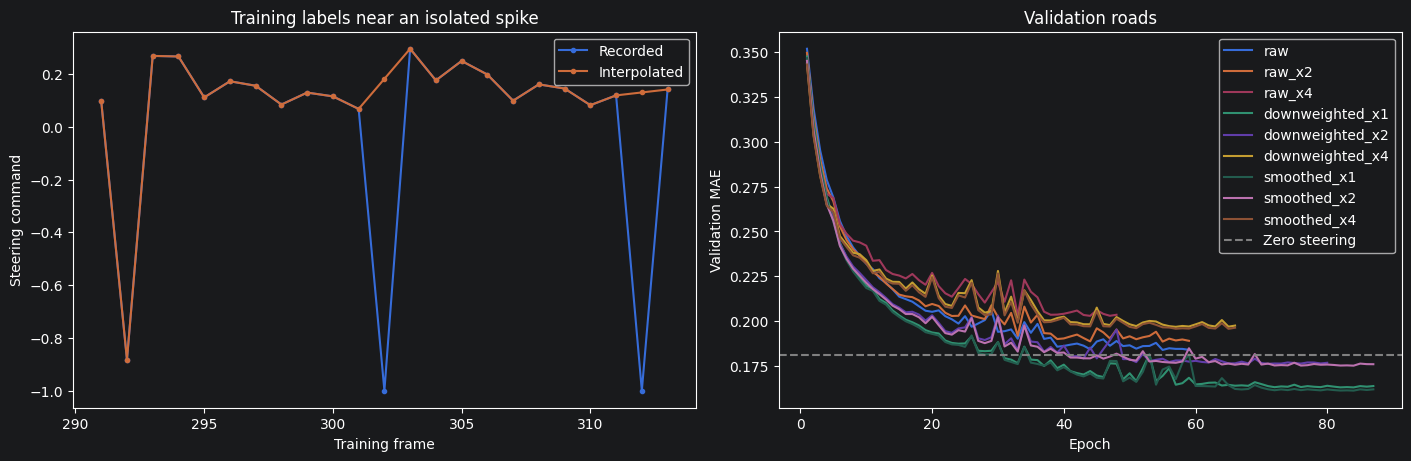

In [8]:
import matplotlib.pyplot as plt

fit = rows["train"]
example = next((r for r in fit if r["raw"] != r["target"]), fit[0])
segment = [r for r in fit if r["route"] == example["route"] and abs(r["frame"] - example["frame"]) <= 11]
fig, (trace_ax, score_ax) = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")
for key, label in (("raw", "Recorded"), ("target", "Interpolated")):
    trace_ax.plot([r["frame"] for r in segment], [r[key] for r in segment], marker=".", label=label)
trace_ax.set(title="Training labels near an isolated spike", xlabel="Training frame", ylabel="Steering command")
trace_ax.legend()
for recipe in results:
    log = (run_dir / f"{recipe}-epochs.jsonl").read_text(encoding="utf-8")
    curve = [json.loads(line) for line in log.splitlines()]
    score_ax.plot([r["epoch"] for r in curve], [r["validation"]["mae"] for r in curve], label=recipe)
val_baseline = float(np.abs(validation_targets).mean())
score_ax.axhline(val_baseline, linestyle="--", color="gray", label="Zero steering")
score_ax.set(title="Validation roads", xlabel="Epoch", ylabel="Validation MAE")
score_ax.legend()
fig.savefig(run_dir / "experiment.png", dpi=150)
plt.show()